## Question 2

##### 2.1

In [1]:
#import libraries 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.naive_bayes import ComplementNB
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

In [2]:
#load data
df = pd.read_csv(r"C:\Users\jessb\OneDrive\Desktop\University\University\CTI\Honours\Semester 2\ITNPA4\Assignment\Datasets\cleaned_abstracts.csv")

In [3]:
#train test splits
le = LabelEncoder()
y = le.fit_transform(df["Label"])

X_train, X_test, y_train, y_test = train_test_split(df["clean_abstract"], y, test_size=0.2, random_state=42, stratify=y)

tfidf_vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

print("Train:", X_train_tfidf.shape, "Test:", X_test_tfidf.shape)

Train: (900, 5000) Test: (225, 5000)


In [4]:
#different models to test (including baseline model)
models = {
    "Logistic Regression (baseline model)": LogisticRegression(max_iter=1000, random_state=42),
    "Linear SVM": LinearSVC(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "Complement Naive Bayes": ComplementNB(),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = []
predictions = {}

for name, model in models.items():
    model.fit(X_train_tfidf, y_train)
    y_pred = model.predict(X_test_tfidf)
    predictions[name] = y_pred

    report = classification_report(y_test, y_pred, target_names=le.classes_, output_dict=True)
    cv_f1 = cross_val_score(model, X_train_tfidf, y_train, cv=cv, scoring='f1_macro')

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "AI precision": report["ai"]["precision"],
        "AI recall": report["ai"]["recall"],
        "AI F1": report["ai"]["f1-score"],
        "Macro-F1 (test)": report["macro avg"]["f1-score"],
        "Macro-F1 (5-fold CV)": cv_f1.mean(),
    })

results_df = pd.DataFrame(results).set_index("Model").round(3)
print(results_df)    

                                      Accuracy  AI precision  AI recall  \
Model                                                                     
Logistic Regression (baseline model)     0.836         1.000      0.213   
Linear SVM                               0.916         0.889      0.681   
Random Forest                            0.907         0.964      0.574   
Gradient Boosting                        0.907         0.825      0.702   
Complement Naive Bayes                   0.889         0.844      0.574   

                                      AI F1  Macro-F1 (test)  \
Model                                                          
Logistic Regression (baseline model)  0.351            0.628   
Linear SVM                            0.771            0.860   
Random Forest                         0.720            0.832   
Gradient Boosting                     0.759            0.850   
Complement Naive Bayes                0.684            0.808   

                         

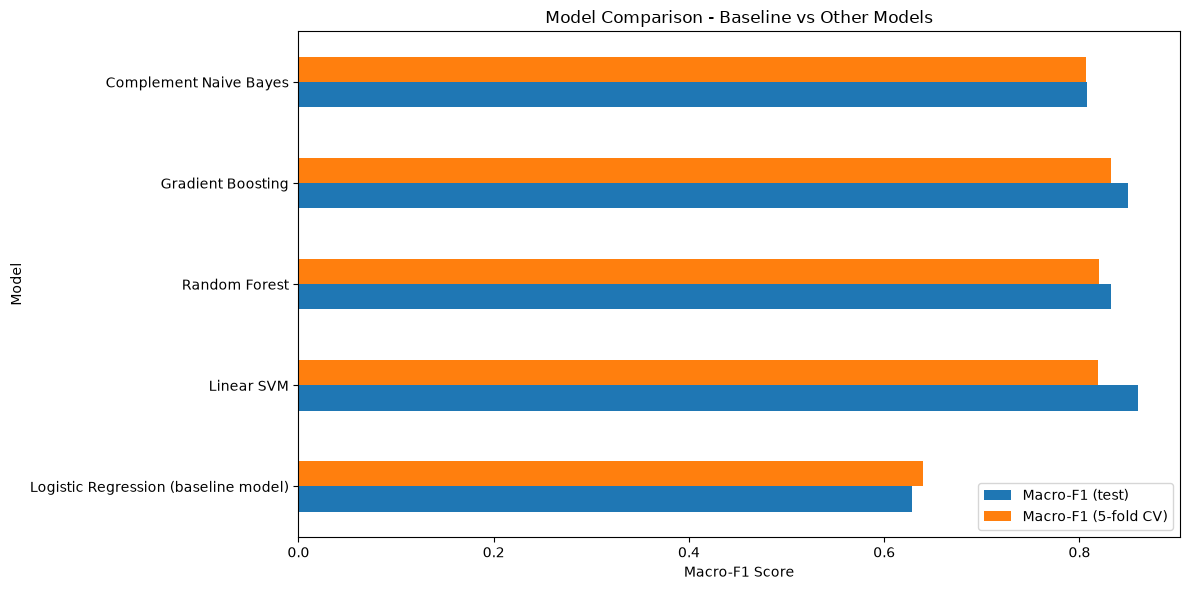

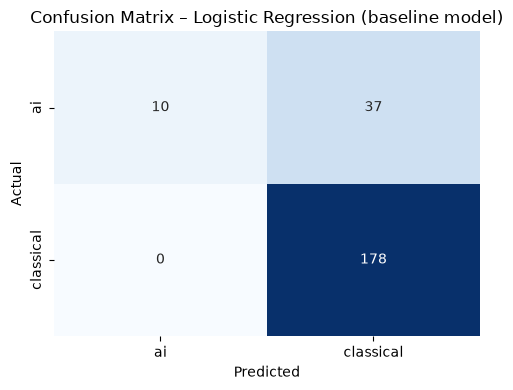

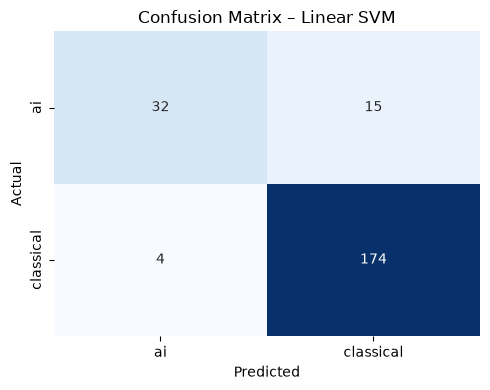

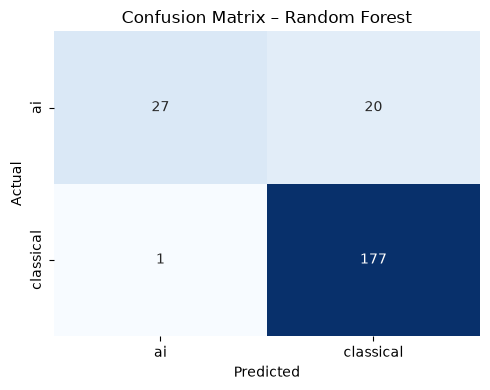

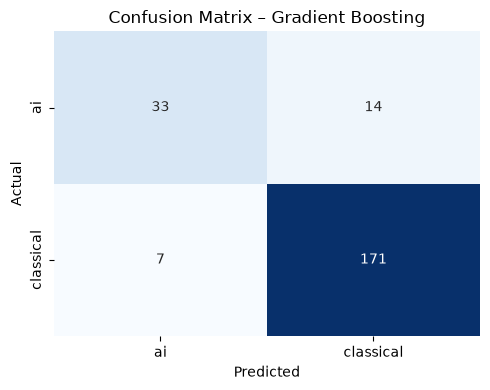

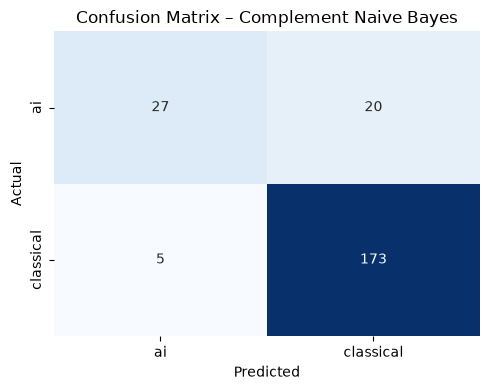

In [5]:
#visualize results
results_df[["Macro-F1 (test)", "Macro-F1 (5-fold CV)"]].plot(kind="barh", figsize=(12, 6))
plt.xlabel("Macro-F1 Score")
plt.title("Model Comparison - Baseline vs Other Models")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

#confusion matrix for each model
for name, y_pred in predictions.items():
    plt.figure(figsize=(5, 4))
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=le.classes_, yticklabels=le.classes_)
    plt.title(f"Confusion Matrix – {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()

##### 2.2

In [6]:
# pipeline
pipeline = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("clf", LinearSVC(random_state=42)),
])

#parameters to test
param_grid = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "tfidf__max_features": [5000, None],
    "clf__C": [0.1, 1, 10],
    "clf__class_weight": [None, "balanced"],
}

In [7]:
# grid search
grid = GridSearchCV(pipeline, param_grid, cv=cv, scoring="f1_macro", n_jobs=-1)
grid.fit(X_train, y_train)          # cleaned text, the pipeline does TF-IDF

print("Best parameters:", grid.best_params_)
print("Best CV macro-F1: %.3f" % grid.best_score_)

Best parameters: {'clf__C': 10, 'clf__class_weight': None, 'tfidf__max_features': None, 'tfidf__ngram_range': (1, 2)}
Best CV macro-F1: 0.849


In [8]:
#top 10 results from grid search
grid_results = pd.DataFrame(grid.cv_results_)
grid_results[["params", "mean_test_score", "std_test_score"]].sort_values(
    "mean_test_score", ascending=False).head(10).round(3)

,params,mean_test_score,std_test_score
19,"{'clf__C': 10, 'clf__class_weight': None, 'tfi...",0.849,0.030
23,"{'clf__C': 10, 'clf__class_weight': 'balanced'...",0.845,0.021
9,"{'clf__C': 1, 'clf__class_weight': None, 'tfid...",0.843,0.040
15,"{'clf__C': 1, 'clf__class_weight': 'balanced',...",0.837,0.015
17,"{'clf__C': 10, 'clf__class_weight': None, 'tfi...",0.837,0.018
21,"{'clf__C': 10, 'clf__class_weight': 'balanced'...",0.833,0.011
11,"{'clf__C': 1, 'clf__class_weight': None, 'tfid...",0.833,0.029
13,"{'clf__C': 1, 'clf__class_weight': 'balanced',...",0.830,0.013
10,"{'clf__C': 1, 'clf__class_weight': None, 'tfid...",0.829,0.034
22,"{'clf__C': 10, 'clf__class_weight': 'balanced'...",0.826,0.026


In [9]:
#compare tuned model with default Linear SVM
y_pred_tuned = grid.predict(X_test)
report = classification_report(y_test, y_pred_tuned, target_names=le.classes_, output_dict=True)

comparison = pd.DataFrame({
    "Linear SVM (default)": results_df.loc["Linear SVM"],
    "Linear SVM (tuned)": {
        "Accuracy": accuracy_score(y_test, y_pred_tuned),
        "AI precision": report["ai"]["precision"],
        "AI recall": report["ai"]["recall"],
        "AI F1": report["ai"]["f1-score"],
        "Macro-F1 (test)": report["macro avg"]["f1-score"],
        "Macro-F1 (5-fold CV)": grid.best_score_,
    },
}).T.round(3)
comparison

,Accuracy,AI precision,AI recall,AI F1,Macro-F1 (test),Macro-F1 (5-fold CV)
Linear SVM (default),0.916,0.889,0.681,0.771,0.860,0.819
Linear SVM (tuned),0.920,0.892,0.702,0.786,0.868,0.849


              precision    recall  f1-score   support

          ai       0.89      0.70      0.79        47
   classical       0.93      0.98      0.95       178

    accuracy                           0.92       225
   macro avg       0.91      0.84      0.87       225
weighted avg       0.92      0.92      0.92       225



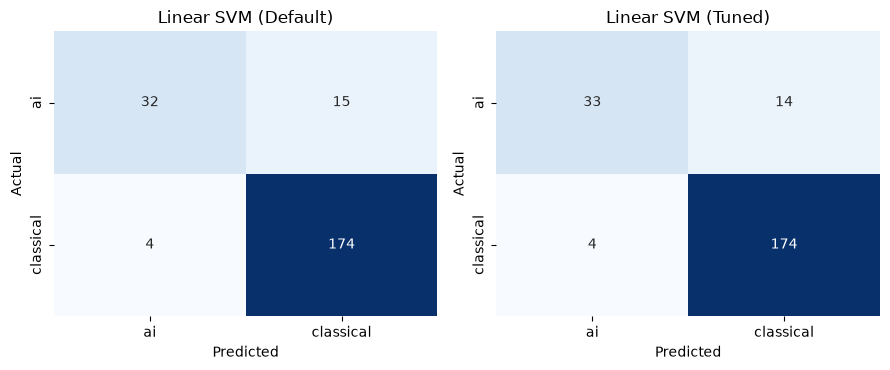

In [10]:
#classification report for the tuned model
print(classification_report(y_test, y_pred_tuned, target_names=le.classes_))

# confusion matrices before and after tuning
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, (title, y_pred) in zip(axes, [("Linear SVM (Default)", predictions["Linear SVM"]),
                                      ("Linear SVM (Tuned)", y_pred_tuned)]):
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=le.classes_, yticklabels=le.classes_, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

In [11]:
# save model for app (Q2.3_app.py)
joblib.dump({"model": grid.best_estimator_, "classes": list(le.classes_)}, "best_model.joblib")
print("Saved best_model.joblib")

Saved best_model.joblib
